# BƯỚC 5.2: XEM DỮ LIỆU MÔ PHỎNG TRƯỚC KHI LÀM CF (data/simulated/)
---
Notebook 01 sinh ra một bộ dữ liệu tương tác **mô phỏng** để thay cho log thật (ứng dụng mới chạy nên log thật gần như trống). Trước khi huấn luyện CF ở **notebook 03**, notebook này xem kỹ dữ liệu đó. Notebook này **chỉ đọc** các file đó và trả lời: dữ liệu mô phỏng **trông như thế nào**, mỗi file có những cột gì, phần nào **mô hình CF được thấy**, phần nào là **"sự thật" ẩn** chỉ dùng để chấm điểm.

| File | Nội dung | CF có thấy không? |
|---|---|---|
| `users.csv` | 3.000 người dùng mô phỏng: hồ sơ (nhóm nghề, kỹ năng, kinh nghiệm, thành phố) + **khẩu vị ẩn** | Hồ sơ: CBF dùng · Khẩu vị: **ẩn** |
| `jobs_hidden.csv` | Thuộc tính ẩn của từng tin: loại công ty, thương hiệu, độ hấp dẫn, ngày mở / đóng | **ẩn** (trừ ngày mở / đóng) |
| `impressions.csv` | Mỗi dòng = một tin được **hiển thị** cho một người dùng | không (dùng để phân tích thiên lệch) |
| `interactions_alpha0.5.csv` | Mỗi dòng = một lần **bấm xem / quan tâm / ứng tuyển** | ✅ **đây là thứ CF học** |
| `true_utility_alpha0.5.npy` | Ma trận **mức thích thật** U (3.000 × số tin) | **ẩn**, chỉ dùng để tính Oracle-P@10 |
| `z_content.npy`, `z_hidden.npy`, `impression_draws.npy` | Thành phần của U và số ngẫu nhiên của phễu, để notebook 03 sinh lại dữ liệu ở mức α khác | **ẩn** |
| `config.json` | Tham số mô phỏng; notebook 03 ghi thêm tham số ALS đã chọn | |

## 1. Nạp các file

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 170)
pd.set_option('display.max_colwidth', 60)
ROOT = os.path.abspath(os.path.join('..', '..'))
SIM = os.path.join(ROOT, 'data', 'simulated')
if not os.path.exists(os.path.join(SIM, 'config.json')):
    raise FileNotFoundError("Chưa có data/simulated/: hãy chạy notebook 01 trước.")

config = json.load(open(os.path.join(SIM, 'config.json'), encoding='utf-8'))
users = pd.read_csv(os.path.join(SIM, 'users.csv'))
jobs_h = pd.read_csv(os.path.join(SIM, 'jobs_hidden.csv'))
imps = pd.read_csv(os.path.join(SIM, 'impressions.csv'))
events = pd.read_csv(os.path.join(SIM, 'interactions_alpha0.5.csv'))
U = np.load(os.path.join(SIM, 'true_utility_alpha0.5.npy')).astype(np.float32)   # lưu dạng float16 cho nhẹ
clean = pd.read_csv(os.path.join(ROOT, 'data', 'notebook', 'content_base', 'jobs_clean.csv')).set_index('job_id')

users['skills'] = users['skills'].fillna('').map(lambda s: [x.strip() for x in s.split(',') if x.strip()])
users['taste'] = users['taste'].map(json.loads)
job_idx = {j: i for i, j in enumerate(jobs_h['job_id'])}            # thứ tự tin = thứ tự cột của U
events['job_idx'] = events['job_id'].map(job_idx)
imps['job_idx'] = imps['job_id'].map(job_idx)
TYPES = config['company_types']
VAL, TEST = config['val_start_day'], config['test_start_day']

files = pd.DataFrame([
    (f, os.path.getsize(os.path.join(SIM, f)) / 1e6,
     {'users.csv': len(users), 'jobs_hidden.csv': len(jobs_h), 'impressions.csv': len(imps),
      'interactions_alpha0.5.csv': len(events), 'true_utility_alpha0.5.npy': f"{U.shape[0]:,} × {U.shape[1]:,}"}.get(f, '-'))
    for f in sorted(os.listdir(SIM))], columns=['File', 'MB', 'Số dòng']).set_index('File')
display(files.round(1))
print(f"Ngày chụp dữ liệu {config['snapshot']} | giai đoạn mô phỏng {config['n_days']} ngày từ {config['snapshot_day0']} | "
      f"validation từ ngày {VAL}, test từ ngày {TEST} | seed {config['seed']}")

,MB,Số dòng
File,,
config.json,0.0,-
impression_draws.npy,6.4,-
impressions.csv,13.5,402891
interactions_alpha0.5.csv,1.2,28136
jobs_hidden.csv,0.3,3675
true_utility_alpha0.5.npy,22.1,"3,000 × 3,675"
users.csv,0.5,3000
z_content.npy,44.1,-
z_hidden.npy,44.1,-


Ngày chụp dữ liệu 2026-11-15 | giai đoạn mô phỏng 55 ngày từ 2026-09-21 | validation từ ngày 38, test từ ngày 45 | seed 42


## 2. Người dùng mô phỏng (`users.csv`)

| Cột | Ý nghĩa | Ai dùng |
|---|---|---|
| `domain` | Nhóm nghề người dùng tìm (Backend, Data/AI...) | sinh phiên tìm kiếm |
| `skills`, `exp`, `city` | Hồ sơ: kỹ năng, số năm kinh nghiệm, thành phố mong muốn | **CBF** chấm điểm nội dung |
| `activity` | Mức độ hoạt động: trung bình số phiên trong 55 ngày | sinh số phiên |
| `taste_cluster`, `taste` | **Khẩu vị ẩn**: tỷ lệ thích 4 loại công ty (Startup, Product, Outsourcing, Tài chính / DN lớn); người cùng cụm có khẩu vị gần nhau | **ẩn**: CF phải tự học ra từ hành vi |
| `brand_sens` | **Ẩn**: mức coi trọng thương hiệu công ty (0-1) | **ẩn** |

,user_id,domain,skills,exp,city,activity,taste_cluster,taste,brand_sens
0,0,Data/AI,"Power BI, MongoDB, Terraform",1.32,Hà Nội,3.66,4,0.47 / 0.20 / 0.32 / 0.01,0.45
1,1,DevOps/Cloud,"Node.js, AWS, Bash, System Administration, Ansible",3.92,Hà Nội,10.35,4,0.36 / 0.20 / 0.39 / 0.05,0.39
2,2,Frontend/Mobile,"Docker, Postman, Angular, Java, CI/CD, Photoshop, Kotlin",2.26,Hà Nội,6.55,4,0.35 / 0.24 / 0.39 / 0.02,0.88
3,3,DevOps/Cloud,"VMware, SQL, Git, Jenkins, Docker",1.98,Hồ Chí Minh,5.30,1,0.29 / 0.21 / 0.42 / 0.07,0.28
4,4,ERP/IT Support,"PostgreSQL, Pandas, LLM, SQL, An Ninh Mạng",3.68,Hồ Chí Minh,3.17,2,0.56 / 0.05 / 0.37 / 0.03,0.15


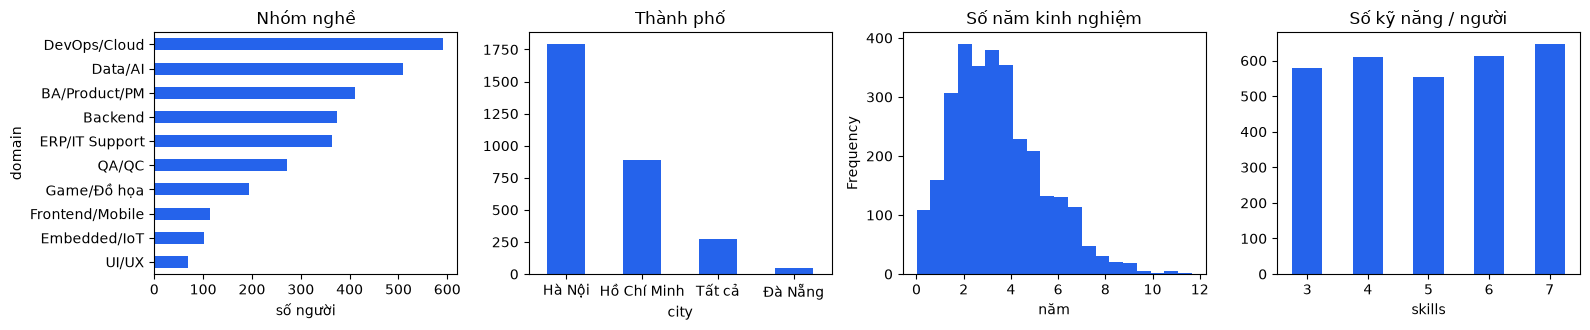

In [2]:
show = users.head(5).copy()
show['skills'] = show['skills'].map(', '.join)
show['taste'] = show['taste'].map(lambda t: ' / '.join(f"{x:.2f}" for x in t))
display(show.round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
users['domain'].value_counts().sort_values().plot.barh(ax=axes[0], color='#2563eb'); axes[0].set(title='Nhóm nghề', xlabel='số người')
users['city'].value_counts().plot.bar(ax=axes[1], color='#2563eb'); axes[1].set(title='Thành phố'); axes[1].tick_params(axis='x', rotation=0)
users['exp'].plot.hist(bins=20, ax=axes[2], color='#2563eb'); axes[2].set(title='Số năm kinh nghiệm', xlabel='năm')
users['skills'].map(len).value_counts().sort_index().plot.bar(ax=axes[3], color='#2563eb'); axes[3].set(title='Số kỹ năng / người'); axes[3].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Khẩu vị ẩn theo cụm.** Mỗi người thuộc 1 trong 6 cụm; khẩu vị của người = 80% khẩu vị của cụm + 20% ngẫu nhiên riêng. Bảng dưới là khẩu vị trung bình từng cụm: đây chính là "**người giống nhau**" mà CF cần phát hiện, trong khi CBF (chỉ đọc hồ sơ) không thể biết.

In [3]:
taste = np.stack(users['taste'].values)
by_cluster = pd.DataFrame(taste, columns=TYPES).groupby(users['taste_cluster']).mean()
by_cluster.insert(0, 'Số người', users['taste_cluster'].value_counts().sort_index())
by_cluster['Thích nhất'] = by_cluster[TYPES].idxmax(axis=1)
display(by_cluster.round(2).style.background_gradient(subset=TYPES, cmap='Blues', axis=None))

,Số người,Startup,Product,Outsourcing,Tài chính / DN lớn,Thích nhất
taste_cluster,,,,,,
0,511,0.180000,0.310000,0.440000,0.080000,Outsourcing
1,455,0.340000,0.250000,0.360000,0.050000,Outsourcing
2,520,0.570000,0.050000,0.330000,0.050000,Startup
3,518,0.050000,0.650000,0.200000,0.100000,Product
4,510,0.360000,0.250000,0.340000,0.050000,Startup
5,486,0.050000,0.840000,0.050000,0.060000,Product


## 3. Thuộc tính ẩn của tin (`jobs_hidden.csv`)

| Cột | Ý nghĩa |
|---|---|
| `domain` | Nhóm nghề của tin (từ `configs/dictionaries/job_domains.yaml`) |
| `open_day`, `close_day` | Ngày tin bắt đầu / ngừng được hiển thị (mở 45 ngày trước hạn nộp thật) |
| `company_type` | **Ẩn**: loại công ty, gán ngẫu nhiên theo **công ty** (các tin cùng công ty cùng loại) |
| `brand` | **Ẩn**: độ nổi tiếng của công ty (chuẩn ~ N(0, 1)) |
| `quality` | **Ẩn**: độ hấp dẫn riêng của tin (chuẩn ~ N(0; 0,5)) |

,job_id,domain,open_day,close_day,company_type,brand,quality,title,company_name
0,topcv_2314643,Data/AI,0,37,Outsourcing,-1.60,-0.33,Full-Stack Web Engineer Intern/Fresher (AI Coding: PHP /...,ZIGExN VeNtura
1,topcv_2314547,Embedded/IoT,0,37,Product,0.14,-0.04,Kỹ Sư Hệ Thống Nhúng,Điện tử R&P
2,topcv_2321616,UI/UX,0,45,Tài chính / DN lớn,0.45,0.21,UI/UX Designer - Mobile App,FOXSCORE
3,topcv_2315450,Data/AI,0,37,Outsourcing,-0.23,-0.01,Business Analyst - Data Hệ Thống Phân Phối - Chế Độ Tốt,THƯƠNG MẠI QUỐC TẾ LB GLOBAL
4,topcv_2315936,QA/QC,0,38,Startup,-1.62,-0.25,Junior QA Tester (Manual Testing),VODAPLAY


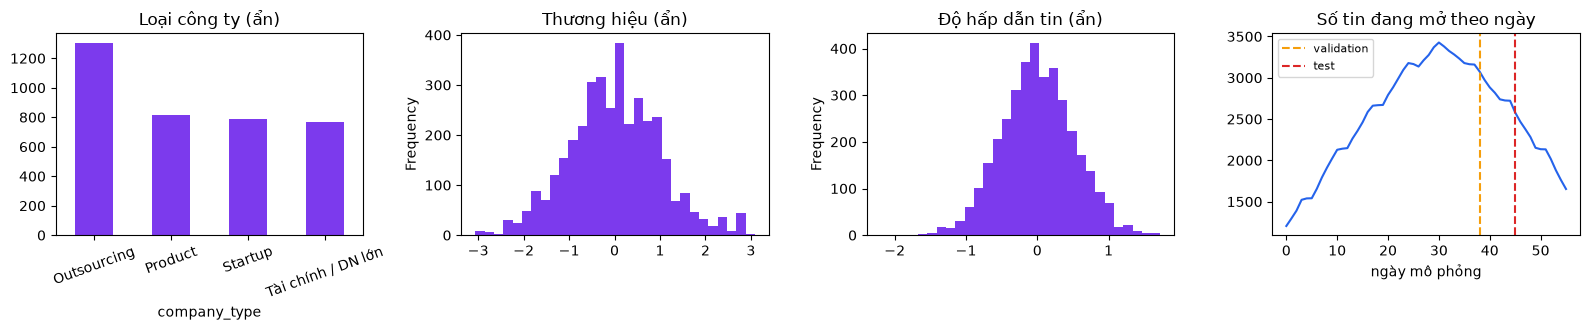

In [4]:
display(jobs_h.head(5).merge(clean[['title', 'company_name']], left_on='job_id', right_index=True, how='left').round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
jobs_h['company_type'].value_counts().plot.bar(ax=axes[0], color='#7c3aed'); axes[0].set(title='Loại công ty (ẩn)'); axes[0].tick_params(axis='x', rotation=20)
jobs_h['brand'].plot.hist(bins=30, ax=axes[1], color='#7c3aed'); axes[1].set(title='Thương hiệu (ẩn)')
jobs_h['quality'].plot.hist(bins=30, ax=axes[2], color='#7c3aed'); axes[2].set(title='Độ hấp dẫn tin (ẩn)')
alive = [((jobs_h['open_day'] <= d) & (jobs_h['close_day'] >= d)).sum() for d in range(config['n_days'] + 1)]
axes[3].plot(alive, color='#2563eb'); axes[3].axvline(VAL, color='#f59e0b', ls='--', label='validation'); axes[3].axvline(TEST, color='#dc2626', ls='--', label='test')
axes[3].set(title='Số tin đang mở theo ngày', xlabel='ngày mô phỏng'); axes[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Lượt hiển thị (`impressions.csv`)
Mỗi **phiên** (một người, một ngày) hiển thị khoảng 20 tin **đang mở**, từ 3 nguồn rồi xáo trộn thứ tự:
- **search** (10 tin): tin cùng nhóm nghề, chọn ngẫu nhiên, mô phỏng người dùng gõ từ khóa;
- **feed** (6 tin): lấy từ top-30 theo điểm nội dung có nhiễu, mô phỏng **một hệ CBF đang chạy**;
- **explore** (4 tin): ngẫu nhiên trong toàn kho.

402,891 lượt hiển thị | 18,399 phiên | trung bình 21.9 tin/phiên | 3,000 người dùng | mỗi người trung bình 6.1 phiên


,user_id,job_id,day,position,source,job_idx
0,0,topcv_2344274,28,0,feed,2848
1,0,vietnamworks_2100871,28,1,feed,1382
2,0,topcv_2348417,28,2,feed,3434
3,0,topcv_2338484,28,3,feed,2259
4,0,topcv_2333656,28,4,explore,1824
5,0,topcv_2278325,28,5,feed,3201


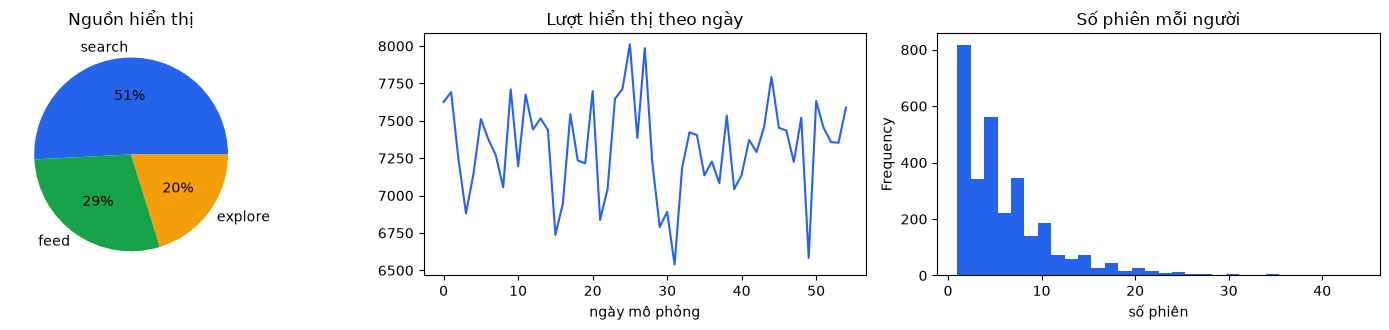

In [5]:
sessions = imps.groupby(['user_id', 'day']).size()
print(f"{len(imps):,} lượt hiển thị | {len(sessions):,} phiên | trung bình {sessions.mean():.1f} tin/phiên | "
      f"{imps['user_id'].nunique():,} người dùng | mỗi người trung bình {imps.groupby('user_id')['day'].nunique().mean():.1f} phiên")
display(imps.head(6))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
imps['source'].value_counts().plot.pie(ax=axes[0], autopct='%1.0f%%', colors=['#2563eb', '#16a34a', '#f59e0b']); axes[0].set(title='Nguồn hiển thị', ylabel='')
imps.groupby('day').size().plot(ax=axes[1], color='#2563eb'); axes[1].set(title='Lượt hiển thị theo ngày', xlabel='ngày mô phỏng')
imps.groupby('user_id')['day'].nunique().plot.hist(bins=30, ax=axes[2], color='#2563eb'); axes[2].set(title='Số phiên mỗi người', xlabel='số phiên')
plt.tight_layout(); plt.show()

## 5. Tương tác (`interactions_alpha0.5.csv`): thứ CF thực sự học
Mỗi lượt hiển thị đi qua **phễu hành vi**: có nhìn tới tin không (tin càng ở dưới càng ít được nhìn) ➔ có bấm xem không ➔ nếu bấm thì có lưu / ứng tuyển không. Xác suất mỗi bước tăng theo **mức thích thật U**. Mỗi lượt hiển thị sinh **tối đa 1 sự kiện** (hành động sâu nhất).

In [6]:
display(events.drop(columns='job_idx').head(6))
funnel = pd.DataFrame({
    'Số lượng': [len(imps), len(events), int(events['event'].isin(['save', 'apply']).sum()), int((events['event'] == 'apply').sum())],
}, index=['Hiển thị', 'Có hành động (xem / lưu / ứng tuyển)', 'Lưu hoặc ứng tuyển', 'Ứng tuyển'])
funnel['% so với hiển thị'] = (funnel['Số lượng'] / len(imps) * 100).round(2)
display(funnel)
print("Phân bố sự kiện:", events['event'].value_counts().to_dict())

,user_id,job_id,day,position,source,event,weight
0,0,topcv_2338484,28,3,feed,click,1.0
1,1,vietnamworks_2111440,0,14,search,click,1.0
2,1,topcv_2321483,6,3,feed,click,1.0
3,1,topcv_2291526,6,5,feed,click,1.0
4,1,vietnamworks_2110829,6,7,search,apply,5.0
5,1,topcv_1352985,13,3,feed,apply,5.0


,Số lượng,% so với hiển thị
Hiển thị,402891,100.00
Có hành động (xem / lưu / ứng tuyển),28136,6.98
Lưu hoặc ứng tuyển,8818,2.19
Ứng tuyển,2999,0.74


Phân bố sự kiện: {'click': 19318, 'save': 5819, 'apply': 2999}


### 5.1. Thiên lệch vị trí và thiên lệch nguồn
Nếu người dùng chỉ bấm theo sở thích thì tỷ lệ bấm ở mọi vị trí phải gần như nhau (vì thứ tự đã xáo trộn). Thực tế tỷ lệ giảm dần theo vị trí: đây là **thiên lệch vị trí** được cài vào mô phỏng, giống người thật ít cuộn xuống dưới.

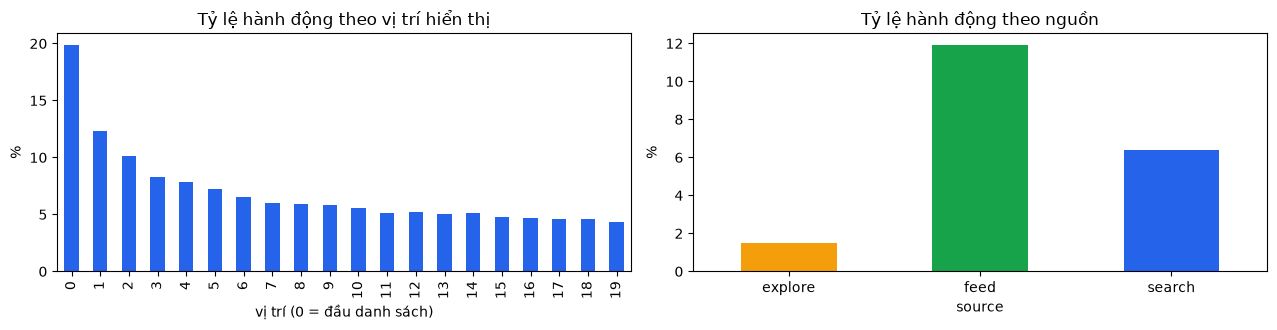

Vị trí 0: 19.9% | vị trí 19: 4.4%  ➔ tin đầu danh sách được bấm nhiều gấp 4.6 lần
Theo nguồn: {'explore': '1.5%', 'feed': '11.9%', 'search': '6.4%'}  (feed cao nhất vì hệ CBF chọn tin hợp hồ sơ)


In [7]:
key = ['user_id', 'job_id', 'day', 'position']
imps_ev = imps.merge(events[key + ['event']], on=key, how='left')
imps_ev['acted'] = imps_ev['event'].notna()
ctr_pos = imps_ev.groupby('position')['acted'].mean()
ctr_src = imps_ev.groupby('source')['acted'].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
(ctr_pos * 100).plot.bar(ax=axes[0], color='#2563eb'); axes[0].set(title='Tỷ lệ hành động theo vị trí hiển thị', xlabel='vị trí (0 = đầu danh sách)', ylabel='%')
(ctr_src * 100).plot.bar(ax=axes[1], color=['#f59e0b', '#16a34a', '#2563eb']); axes[1].set(title='Tỷ lệ hành động theo nguồn', ylabel='%'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print(f"Vị trí 0: {ctr_pos.iloc[0]:.1%} | vị trí {ctr_pos.index[-1]}: {ctr_pos.iloc[-1]:.1%}  ➔ tin đầu danh sách được bấm nhiều gấp {ctr_pos.iloc[0] / ctr_pos.iloc[-1]:.1f} lần")
print("Theo nguồn:", {k: f"{v:.1%}" for k, v in ctr_src.items()}, " (feed cao nhất vì hệ CBF chọn tin hợp hồ sơ)")

### 5.2. Ma trận người dùng × tin: thưa và "đuôi dài"

,Giá trị
Chỉ số,
Kích thước ma trận,"3,000 người × 3,675 tin = 11,025,000 ô"
Ô có giá trị (cặp người–tin),"25,802"
Độ thưa,99.766%
Sự kiện / người (trung vị; 90% người ≤),6; 21
Người không có sự kiện nào,152 (5.1%)
10% tin phổ biến nhất chiếm,32.8% sự kiện
Tin chưa từng được bấm,644 (17.5%)


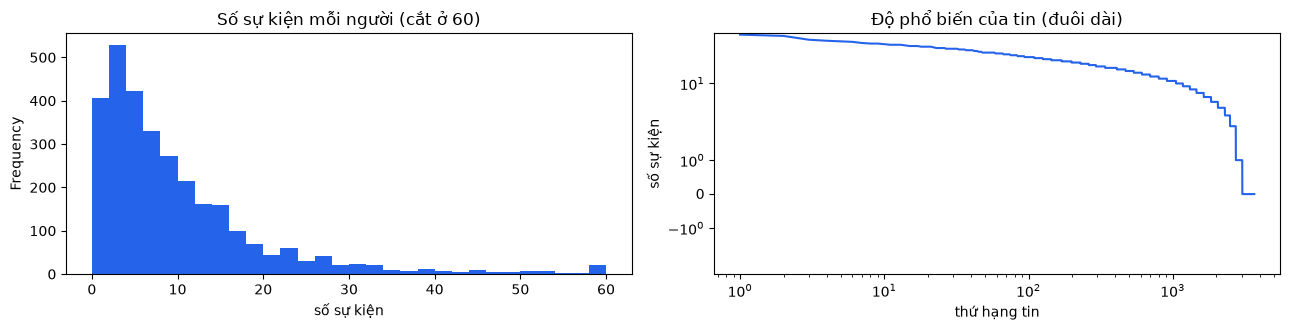

In [8]:
pairs = events.groupby(['user_id', 'job_id']).size()
per_user = events.groupby('user_id').size().reindex(users['user_id'], fill_value=0)
per_job = events.groupby('job_id').size().reindex(jobs_h['job_id'], fill_value=0).sort_values(ascending=False)
top10 = per_job.iloc[:len(per_job) // 10].sum() / per_job.sum()
stats = pd.DataFrame([
    ('Kích thước ma trận', f"{len(users):,} người × {len(jobs_h):,} tin = {len(users) * len(jobs_h):,} ô"),
    ('Ô có giá trị (cặp người–tin)', f"{len(pairs):,}"),
    ('Độ thưa', f"{1 - len(pairs) / (len(users) * len(jobs_h)):.3%}"),
    ('Sự kiện / người (trung vị; 90% người ≤)', f"{per_user.median():.0f}; {per_user.quantile(0.9):.0f}"),
    ('Người không có sự kiện nào', f"{(per_user == 0).sum():,} ({(per_user == 0).mean():.1%})"),
    ('10% tin phổ biến nhất chiếm', f"{top10:.1%} sự kiện"),
    ('Tin chưa từng được bấm', f"{(per_job == 0).sum():,} ({(per_job == 0).mean():.1%})"),
], columns=['Chỉ số', 'Giá trị']).set_index('Chỉ số')
display(stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
per_user.clip(upper=60).plot.hist(bins=30, ax=axes[0], color='#2563eb'); axes[0].set(title='Số sự kiện mỗi người (cắt ở 60)', xlabel='số sự kiện')
axes[1].plot(np.arange(1, len(per_job) + 1), per_job.values, color='#2563eb')
axes[1].set(title='Độ phổ biến của tin (đuôi dài)', xlabel='thứ hạng tin', ylabel='số sự kiện', xscale='log', yscale='symlog')
plt.tight_layout(); plt.show()

### 5.3. Theo thời gian: train / validation / test và tin mới
Notebook 01, 07 chia **theo thời gian** như ngoài đời: học trên quá khứ, đánh giá trên tương lai. Tin xuất hiện lần đầu ở giai đoạn test mà chưa ai bấm ở giai đoạn train là **tin mới**: CF không biết gì về chúng.

,Sự kiện,Người dùng,Tin
day,,,
Train (ngày 0-37),19186,2633,2806
Validation (38-44),3721,1255,1655
Test (từ 45),5229,1563,1630


Ở giai đoạn test: 171/5,229 sự kiện (3%) rơi vào tin MỚI (chưa ai bấm ở train) ➔ CF thuần bỏ lỡ hết các tin này


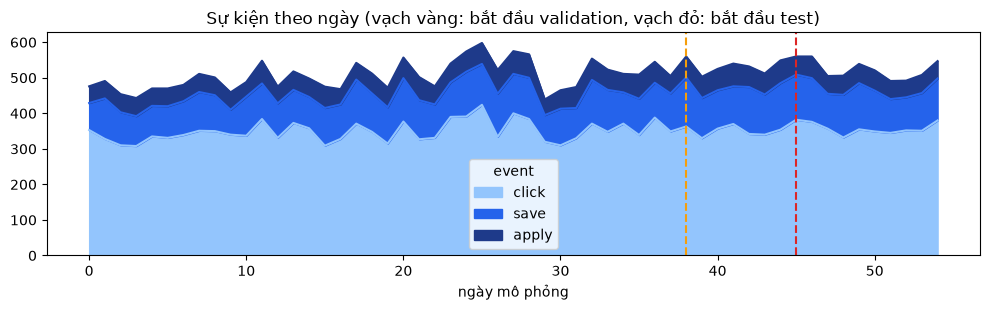

In [9]:
period = pd.cut(events['day'], [-1, VAL - 1, TEST - 1, 10_000], labels=[f'Train (ngày 0-{VAL - 1})', f'Validation ({VAL}-{TEST - 1})', f'Test (từ {TEST})'])
split = events.groupby(period, observed=False).agg(**{'Sự kiện': ('event', 'size'), 'Người dùng': ('user_id', 'nunique'), 'Tin': ('job_id', 'nunique')})
display(split)
train_jobs = set(events.loc[events['day'] < TEST, 'job_id'])
test_ev = events[events['day'] >= TEST]
cold = ~test_ev['job_id'].isin(train_jobs)
print(f"Ở giai đoạn test: {cold.sum():,}/{len(test_ev):,} sự kiện ({cold.mean():.0%}) rơi vào tin MỚI (chưa ai bấm ở train) ➔ CF thuần bỏ lỡ hết các tin này")

fig, ax = plt.subplots(figsize=(10, 3.2))
events.groupby(['day', 'event']).size().unstack(fill_value=0)[['click', 'save', 'apply']].plot.area(ax=ax, color=['#93c5fd', '#2563eb', '#1e3a8a'])
ax.axvline(VAL, color='#f59e0b', ls='--'); ax.axvline(TEST, color='#dc2626', ls='--')
ax.set(title='Sự kiện theo ngày (vạch vàng: bắt đầu validation, vạch đỏ: bắt đầu test)', xlabel='ngày mô phỏng')
plt.tight_layout(); plt.show()

### 5.4. Theo nhóm nghề: mỗi nhóm có bao nhiêu dữ liệu để CF học?
Nhóm càng ít người dùng và sự kiện thì CF càng có ít tín hiệu cho nhóm đó (so với kết quả theo nhóm ở notebook 07, mục 4.1). Nhóm **Khác** (vị trí kinh doanh, tiêu đề không rõ nghề) không có người dùng mô phỏng.
- **CTR** = số sự kiện / số lượt hiển thị của tin thuộc nhóm;
- **Sự kiện / tin**: trung bình mỗi tin của nhóm nhận bao nhiêu lượt bấm / lưu / ứng tuyển.

In [10]:
dom_order = list(users['domain'].value_counts().index) + ['Khác']
by_domain = pd.DataFrame({
    'Số tin': jobs_h['domain'].value_counts(),
    'Số người dùng': users['domain'].value_counts(),
    'Lượt hiển thị': pd.Series(jobs_h['domain'].values[imps['job_idx'].values]).value_counts(),
    'Sự kiện': pd.Series(jobs_h['domain'].values[events['job_idx'].values]).value_counts(),
}).reindex(dom_order).fillna(0).astype(int)
by_domain['% kho tin'] = by_domain['Số tin'] / by_domain['Số tin'].sum()
by_domain['% người dùng'] = by_domain['Số người dùng'] / by_domain['Số người dùng'].sum()
by_domain['CTR'] = by_domain['Sự kiện'] / by_domain['Lượt hiển thị'].replace(0, np.nan)
by_domain['Sự kiện / tin'] = by_domain['Sự kiện'] / by_domain['Số tin'].replace(0, np.nan)
display(by_domain.style.format({'Số tin': '{:,.0f}', 'Số người dùng': '{:,.0f}', 'Lượt hiển thị': '{:,.0f}', 'Sự kiện': '{:,.0f}',
                                '% kho tin': '{:.1%}', '% người dùng': '{:.1%}', 'CTR': '{:.1%}', 'Sự kiện / tin': '{:.1f}'}))
body = by_domain.drop(index='Khác')
print(f"Nhóm nhiều dữ liệu nhất: {body['Sự kiện'].idxmax()} ({int(body['Sự kiện'].max()):,} sự kiện) | "
      f"ít nhất: {body['Sự kiện'].idxmin()} ({int(body['Sự kiện'].min()):,} sự kiện)")

,Số tin,Số người dùng,Lượt hiển thị,Sự kiện,% kho tin,% người dùng,CTR,Sự kiện / tin
DevOps/Cloud,596,591,"74,549","5,397",16.2%,19.7%,7.2%,9.1
Data/AI,519,509,"64,744","4,305",14.1%,17.0%,6.6%,8.3
BA/Product/PM,408,412,"56,060","4,954",11.1%,13.7%,8.8%,12.1
Backend,401,375,"51,159","3,432",10.9%,12.5%,6.7%,8.6
ERP/IT Support,332,364,"46,092","2,975",9.0%,12.1%,6.5%,9.0
QA/QC,280,272,"35,857","2,503",7.6%,9.1%,7.0%,8.9
Game/Đồ họa,196,193,"22,617","1,698",5.3%,6.4%,7.5%,8.7
Frontend/Mobile,132,114,"16,221","1,068",3.6%,3.8%,6.6%,8.1
Embedded/IoT,101,101,"13,196",910,2.7%,3.4%,6.9%,9.0
UI/UX,69,69,"7,703",736,1.9%,2.3%,9.6%,10.7


Nhóm nhiều dữ liệu nhất: DevOps/Cloud (5,397 sự kiện) | ít nhất: UI/UX (736 sự kiện)


## 6. "Sự thật" ẩn: mức thích thật U (`true_utility_alpha0.5.npy`)
$U(u, j) = 0{,}5 \cdot z(\text{Nội dung}) + 0{,}5 \cdot z(\text{Ẩn})$: một nửa do **hồ sơ khớp tin** (CBF thấy được), một nửa do **khẩu vị ẩn** (loại công ty, thương hiệu, độ hấp dẫn; chỉ CF học được qua hành vi). Mô hình **không bao giờ** được đọc U; U chỉ dùng để tính **Oracle-P@10** (gợi ý trúng bao nhiêu tin người dùng thật sự thích nhất).

**Kiểm tra quan trọng nhất của mô phỏng:** hành vi phải phản ánh sở thích. Tin được ứng tuyển phải có U cao hơn tin chỉ được xem, và cao hơn hẳn tin hiển thị mà không ai bấm.

,Số lượt,U trung bình,U trung vị
Hành vi,,,
"0. hiển thị, không bấm",374711,0.913,0.971
1. chỉ xem,19351,1.612,1.633
2. lưu,5828,1.951,1.947
3. ứng tuyển,3007,2.062,2.061


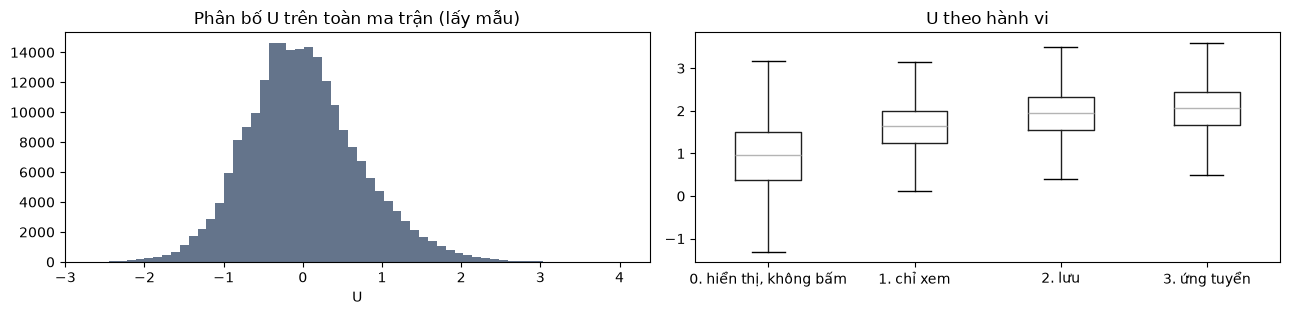

In [11]:
imps_ev['U'] = U[imps_ev['user_id'].values, imps_ev['job_idx'].values]
imps_ev['Hành vi'] = imps_ev['event'].fillna('không bấm').map({'không bấm': '0. hiển thị, không bấm', 'click': '1. chỉ xem', 'save': '2. lưu', 'apply': '3. ứng tuyển'})
u_by = imps_ev.groupby('Hành vi')['U'].agg(['size', 'mean', 'median']).rename(columns={'size': 'Số lượt', 'mean': 'U trung bình', 'median': 'U trung vị'})
display(u_by.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].hist(U.ravel()[::50], bins=60, color='#64748b'); axes[0].set(title='Phân bố U trên toàn ma trận (lấy mẫu)', xlabel='U')
imps_ev.boxplot(column='U', by='Hành vi', ax=axes[1], grid=False, showfliers=False); axes[1].set(title='U theo hành vi', xlabel=''); plt.suptitle('')
plt.tight_layout(); plt.show()

## 7. Ví dụ một người dùng mô phỏng, từ đầu đến cuối
Chọn một người có nhiều sự kiện để thấy cả chuỗi: hồ sơ ➔ khẩu vị ẩn ➔ những gì được hiển thị ➔ những gì đã bấm ➔ so với **10 tin người đó thật sự thích nhất**.

In [12]:
uid = int(per_user[per_user.between(8, 15)].index[0])
u = users.loc[uid]
print(f"NGƯỜI DÙNG {uid}: nhóm {u['domain']} | kỹ năng {', '.join(u['skills'])} | {u['exp']:.1f} năm | {u['city']}")
print("  Khẩu vị ẩn (cụm %d): " % u['taste_cluster'] + ', '.join(f"{t} {x:.2f}" for t, x in zip(TYPES, u['taste'])) + f" | coi trọng thương hiệu {u['brand_sens']:.2f}")
ui = imps_ev[imps_ev['user_id'] == uid]
print(f"  {ui['day'].nunique()} phiên, được hiển thị {len(ui)} tin, bấm {ui['acted'].sum()} lần")

acted = ui[ui['acted']].sort_values('day')
acted = acted.merge(jobs_h[['job_id', 'company_type']], on='job_id').merge(clean[['title']], left_on='job_id', right_index=True)
display(acted[['day', 'position', 'source', 'event', 'title', 'company_type', 'U']].round(2).rename(columns={'title': 'Tin đã bấm'}))

alive_last = (jobs_h['open_day'] <= config['n_days']) & (jobs_h['close_day'] >= TEST)
best = np.argsort(-np.where(alive_last.values, U[uid], -np.inf))[:10]
top = jobs_h.iloc[best][['job_id', 'domain', 'company_type']].merge(clean[['title']], left_on='job_id', right_index=True)
top['U'] = U[uid, best].round(2)
top['Đã được hiển thị?'] = top['job_id'].isin(ui['job_id']).map({True: 'có', False: 'CHƯA'})
print("\n10 tin người này THẬT SỰ thích nhất (theo U, trong các tin còn mở ở giai đoạn test):")
display(top[['title', 'domain', 'company_type', 'U', 'Đã được hiển thị?']])
print(f"➔ {int((top['Đã được hiển thị?'] == 'CHƯA').sum())}/10 tin người này thích nhất CHƯA TỪNG được hiển thị: log không thể cho biết người đó thích chúng.\n"
      "  Đây là lý do đánh giá chỉ trên log bị thiên lệch, và cần Oracle-P@10 (tính từ U) để đo công bằng.")

NGƯỜI DÙNG 2: nhóm Frontend/Mobile | kỹ năng Docker, Postman, Angular, Java, CI/CD, Photoshop, Kotlin | 2.3 năm | Hà Nội
  Khẩu vị ẩn (cụm 4): Startup 0.35, Product 0.24, Outsourcing 0.39, Tài chính / DN lớn 0.02 | coi trọng thương hiệu 0.88
  7 phiên, được hiển thị 154 tin, bấm 9 lần


,day,position,source,event,Tin đã bấm,company_type,U
0,12,11,search,click,Chuyên Viên Phát Triển Phần Mềm (Mobile - Flutter),Startup,1.12
1,14,0,search,save,Junior Frontend Engineer (Shopify),Outsourcing,1.52
2,17,12,feed,click,Nhân Viên ReactJS Front End Developer (Middle),Tài chính / DN lớn,2.25
3,17,13,search,click,Lead Mobile Developer,Startup,1.07
4,32,0,feed,click,Angular Team Lead,Outsourcing,1.88
5,32,11,search,click,Frontend Lead,Product,1.01
6,35,1,search,click,"Lập Trình Web Full Stack Nodejs, PHP",Outsourcing,1.59
7,35,5,feed,save,User Acquisition Executive (Mobile App),Product,1.85
8,52,0,explore,click,Fullstack Tester,Startup,1.04



10 tin người này THẬT SỰ thích nhất (theo U, trong các tin còn mở ở giai đoạn test):


,title,domain,company_type,U,Đã được hiển thị?
2705,UA Marketing Mobile App,Frontend/Mobile,Outsourcing,2.44,CHƯA
212,Nhân Viên ReactJS Front End Developer (Middle),Frontend/Mobile,Tài chính / DN lớn,2.25,có
1361,Junior DevOps Engineer (1-3 Years of Experience),DevOps/Cloud,Outsourcing,2.16,CHƯA
1937,Technical Lead (Android),Frontend/Mobile,Outsourcing,2.15,có
349,System Engineer,DevOps/Cloud,Outsourcing,2.12,CHƯA
389,ANDROID DEVELOPER (Trưởng Nhóm),Frontend/Mobile,Startup,2.11,có
3177,Full Stack Developer (Python/Reactjs),Frontend/Mobile,Outsourcing,2.08,có
2978,Trưởng Nhóm An Ninh Mạng,DevOps/Cloud,Outsourcing,2.02,CHƯA
2650,Android Developer (Kotlin / Jetpack Compose),Frontend/Mobile,Product,2.01,CHƯA
2508,Product Owner Trainee,BA/Product/PM,Startup,1.93,CHƯA


➔ 6/10 tin người này thích nhất CHƯA TỪNG được hiển thị: log không thể cho biết người đó thích chúng.
  Đây là lý do đánh giá chỉ trên log bị thiên lệch, và cần Oracle-P@10 (tính từ U) để đo công bằng.


## 8. Tóm tắt
- Dữ liệu đạt yêu cầu ➔ chuyển sang **notebook 03** để huấn luyện và so sánh các mô hình CF.
- **CF chỉ được học từ `interactions_alpha0.5.csv`**: ai đã xem / lưu / ứng tuyển tin nào, vào ngày nào. Mọi cột "ẩn" (khẩu vị, loại công ty, thương hiệu, U) chỉ dùng để sinh dữ liệu và chấm điểm.
- Dữ liệu có các đặc điểm giống dữ liệu thật: **rất thưa**, **đuôi dài** (một ít tin chiếm phần lớn lượt bấm), **phễu** xem > lưu > ứng tuyển, **thiên lệch vị trí** và **thiên lệch nguồn** (hệ CBF đang chạy quyết định phần lớn tin được thấy), có **tin mới** ở giai đoạn test.
- **Hành vi phản ánh sở thích** (mục 6: U tăng dần từ "không bấm" ➔ "ứng tuyển"), nên học từ hành vi là có ý nghĩa; nhưng phần lớn tin người dùng thích nhất **chưa từng được hiển thị** (mục 7), nên log là một bức tranh **thiếu và lệch**.